# Digital Image Processing — Week 5 · Task 4

**Grup: Nmertgules ve Iliya**

Renk uzayı dönüşümlerini kendimiz yazıyoruz

Her dönüşüm, bir pikselin kanallarını alıp yeni renk uzayındaki kanalları üreten ayrı bir fonksiyondur. Fonksiyonlar bir **dönüşüm tablosunda** tutulur ve tek bir `convert(image, converter)` fonksiyonuna parametre olarak verilir. Python'da fonksiyonlar birinci sınıf nesne olduğu için bu tablo, C++'taki **fonksiyon pointer** dizisinin karşılığıdır. CUDA C++ sürümünde (`06_cuda.ipynb`) aynı yapı gerçek `__device__` fonksiyon pointer'larıyla kurulmuştur.

Üretilen her görüntü `cv2.cvtColor` çıktısıyla sayısal olarak karşılaştırılır ve hata değerleri yazdırılır. **Beklenen hata değeri sıfırdır.** Bunu sağlamak için OpenCV'nin 8 bit görüntülerde kullandığı tam sayı (sabit noktalı) aritmetiği aynen uygulanır.

In [1]:
from pathlib import Path
import urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Repodaki mevcut renkli fotoğrafı kullanıyoruz. Repo kökü çalışma klasöründen yukarı doğru aranır;
# böylece notebook hem repo kökünden hem de week5 içinden çalışır. Repo yoksa (ör. Colab) aynı
# fotoğraf GitHub'dan indirilir.
IMAGE_URL = 'https://raw.githubusercontent.com/Nmertgules/DEEP/main/week4/assets/rocket.jpg'

def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / 'week4' / 'assets' / 'rocket.jpg').is_file():
            return folder
    return None

ROOT = find_repo_root()
if ROOT is None:
    ROOT = Path('DEEP').resolve()
    (ROOT / 'week4' / 'assets').mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(IMAGE_URL, ROOT / 'week4' / 'assets' / 'rocket.jpg')
HERE = ROOT / 'week5'
IMAGE = ROOT / 'week4' / 'assets' / 'rocket.jpg'
OUT = HERE / 'results'
OUT.mkdir(parents=True, exist_ok=True)

bgr = cv2.imread(str(IMAGE), cv2.IMREAD_COLOR)
if bgr is None:
    raise FileNotFoundError(f'Görüntü okunamadı: {IMAGE}')
print(f'OpenCV {cv2.__version__} · Görüntü: {bgr.shape[1]} × {bgr.shape[0]}, {bgr.dtype}')

OpenCV 5.0.0 · Görüntü: 640 × 427, uint8


## Dönüşüm fonksiyonları

| Dönüşüm | Formül (8 bit, OpenCV ile aynı) |
| --- | --- |
| BGR → GRAY | `Y = (3735·B + 19235·G + 9798·R + 2¹⁴) >> 15` |
| BGR → YCrCb | `Y` 14 bit katsayılarla (1868, 9617, 4899); `Cr = ((R−Y)·11682 + 128·2¹⁴ + 2¹³) >> 14`, `Cb = ((B−Y)·9241 + …) >> 14` |
| BGR → YUV | Aynı `Y`; `U = (B−Y)·8061`, `V = (R−Y)·14369` (0.492 ve 0.877'nin 2¹⁴ katı) |
| BGR → XYZ | sRGB/D65 matrisi, katsayılar `round(c·4096)`, 12 bit kaydırma, 0–255'e kırpma |
| BGR → HSV | `V = max`, `S = 255·(V−min)/V`, `H` 0–180 aralığında; bölmeler OpenCV gibi önceden hesaplanmış `round(2¹²·255/i)` ve `round(2¹²·180/(6i))` tablolarıyla |
| YCrCb → BGR | Ters dönüşüm: `R = Y + 1.403·(Cr−128)`, `G = Y − 0.714·(Cr−128) − 0.344·(Cb−128)`, `B = Y + 1.773·(Cb−128)` (2¹⁴ ile ölçeklenmiş tam sayılar) |

Not: OpenCV gri dönüşümde 15 bit, YCrCb/YUV içindeki `Y` için 14 bit katsayı kullanır. Bu yüzden bu ikisi birkaç renkte 1 seviye farklı olabilir; iki ayrı formül bu nedenle yazıldı.

In [2]:
def descale(x, n):
    """Sabit noktalı değeri en yakına yuvarlayarak n bit sağa kaydır (OpenCV CV_DESCALE)."""
    return (x + (1 << (n - 1))) >> n


def saturate(x):
    return np.clip(x, 0, 255).astype(np.uint8)


def channels_of(img):
    return [img[..., i].astype(np.int64) for i in range(img.shape[2])]


def bgr2gray(img):
    b, g, r = channels_of(img)
    return saturate((b * 3735 + g * 19235 + r * 9798 + (1 << 14)) >> 15)


def luma14(b, g, r):
    return descale(b * 1868 + g * 9617 + r * 4899, 14)


def bgr2ycrcb(img):
    b, g, r = channels_of(img)
    y = luma14(b, g, r)
    cr = descale((r - y) * 11682 + (128 << 14), 14)
    cb = descale((b - y) * 9241 + (128 << 14), 14)
    return np.dstack([saturate(y), saturate(cr), saturate(cb)])


def bgr2yuv(img):
    b, g, r = channels_of(img)
    y = luma14(b, g, r)
    u = descale((b - y) * 8061 + (128 << 14), 14)
    v = descale((r - y) * 14369 + (128 << 14), 14)
    return np.dstack([saturate(y), saturate(u), saturate(v)])


SRGB_TO_XYZ_D65 = [[0.412453, 0.357580, 0.180423],
                   [0.212671, 0.715160, 0.072169],
                   [0.019334, 0.119193, 0.950227]]
XYZ_COEFFS = [[int(np.rint(c * 4096)) for c in row] for row in SRGB_TO_XYZ_D65]


def bgr2xyz(img):
    b, g, r = channels_of(img)
    return np.dstack([saturate(descale(r * cr + g * cg + b * cb, 12)) for cr, cg, cb in XYZ_COEFFS])


HSV_SHIFT = 12
S_DIV = np.array([0] + [int(np.rint((255 << HSV_SHIFT) / i)) for i in range(1, 256)], dtype=np.int64)
H_DIV = np.array([0] + [int(np.rint((180 << HSV_SHIFT) / (6.0 * i))) for i in range(1, 256)], dtype=np.int64)


def bgr2hsv(img):
    b, g, r = channels_of(img)
    v = np.maximum(np.maximum(b, g), r)
    diff = v - np.minimum(np.minimum(b, g), r)
    s = descale(diff * S_DIV[v], HSV_SHIFT)
    # Ton: en büyük kanal R ise (G−B), G ise (B−R)+2·diff, B ise (R−G)+4·diff; sonra 180/(6·diff) ile ölçekle.
    h = np.where(v == r, g - b, np.where(v == g, b - r + 2 * diff, r - g + 4 * diff))
    h = descale(h * H_DIV[diff], HSV_SHIFT)
    h = np.where(h < 0, h + 180, h)
    return np.dstack([saturate(h), saturate(s), saturate(v)])


def ycrcb2bgr(img):
    y, cr, cb = channels_of(img)
    cr, cb = cr - 128, cb - 128
    b = y + descale(cb * 29049, 14)
    g = y + descale(cb * -5636 + cr * -11698, 14)
    r = y + descale(cr * 22987, 14)
    return np.dstack([saturate(b), saturate(g), saturate(r)])

## Dönüşüm tablosu ve ortak çağırma fonksiyonu

`CONVERTERS` sözlüğü her dönüşüm adını, bizim fonksiyonumuza ve karşılaştırılacak OpenCV koduna bağlar. `convert`, hangi fonksiyonun çalışacağını bilmez; kendisine verilen fonksiyonu çağırır. C++'ta bu, `typedef void (*ConvFn)(const uchar*, uchar*);` türünde bir pointer dizisiyle yapılır.

In [3]:
CONVERTERS = {
    'BGR → GRAY':  (bgr2gray,  cv2.COLOR_BGR2GRAY),
    'BGR → YCrCb': (bgr2ycrcb, cv2.COLOR_BGR2YCrCb),
    'BGR → YUV':   (bgr2yuv,   cv2.COLOR_BGR2YUV),
    'BGR → XYZ':   (bgr2xyz,   cv2.COLOR_BGR2XYZ),
    'BGR → HSV':   (bgr2hsv,   cv2.COLOR_BGR2HSV),
    'YCrCb → BGR': (ycrcb2bgr, cv2.COLOR_YCrCb2BGR),
}


def convert(image, converter):
    """converter: tablodaki fonksiyonlardan biri (C++'taki fonksiyon pointer'ı gibi)."""
    if image.ndim != 3 or image.shape[2] != 3 or image.dtype != np.uint8:
        raise ValueError('3 kanallı uint8 görüntü bekleniyor.')
    return converter(image)


def errors(ours, reference):
    d = np.abs(ours.astype(np.int64) - reference.astype(np.int64))
    return int(d.sum()), int(d.max())

## Fotoğraf üzerinde karşılaştırma

In [4]:
results = {}
print(f'{"Dönüşüm":<13} {"Hata (SAD)":>10} {"Maks. fark":>10}')
for name, (fn, cv_code) in CONVERTERS.items():
    # Ters dönüşüm YCrCb girdisi ister; girdiyi OpenCV'nin kendi YCrCb çıktısından alıyoruz.
    source = cv2.cvtColor(bgr, cv2.COLOR_BGR2YCrCb) if name.startswith('YCrCb') else bgr
    ours = convert(source, fn)
    reference = cv2.cvtColor(source, cv_code)
    total, worst = errors(ours, reference)
    results[name] = ours
    print(f'{name:<13} {total:>10} {worst:>10}')
    assert total == 0, name

Dönüşüm       Hata (SAD) Maks. fark
BGR → GRAY             0          0
BGR → YCrCb            0          0
BGR → YUV              0          0
BGR → XYZ              0          0


BGR → HSV              0          0


YCrCb → BGR            0          0


## Bütün renkler üzerinde karşılaştırma

Aynı karşılaştırma, 16.777.216 olası 8 bit rengin hepsini içeren 4096 × 4096 görüntüyle tekrarlanır. Ters dönüşümde de bütün olası (Y, Cr, Cb) üçlüleri denenmiş olur.

In [5]:
# 2^24 = 16.777.216 olası 8 bit BGR rengin tamamı, 4096 × 4096 boyutlu tek bir görüntüde.
codes = np.arange(1 << 24, dtype=np.uint32)
all_colors = np.dstack([codes & 255, (codes >> 8) & 255, (codes >> 16) & 255]).astype(np.uint8).reshape(4096, 4096, 3)

print(f'{"Dönüşüm":<13} {"Hata (SAD)":>10} {"Maks. fark":>10}   (16.777.216 renk)')
for name, (fn, cv_code) in CONVERTERS.items():
    total, worst = errors(convert(all_colors, fn), cv2.cvtColor(all_colors, cv_code))
    print(f'{name:<13} {total:>10} {worst:>10}')
    assert total == 0, name
print('Bütün dönüşümlerde hata değeri 0: beklenen sonuç sağlandı.')

Dönüşüm       Hata (SAD) Maks. fark   (16.777.216 renk)


BGR → GRAY             0          0


BGR → YCrCb            0          0


BGR → YUV              0          0


BGR → XYZ              0          0


BGR → HSV              0          0


YCrCb → BGR            0          0
Bütün dönüşümlerde hata değeri 0: beklenen sonuç sağlandı.


## Kanalların görünümü

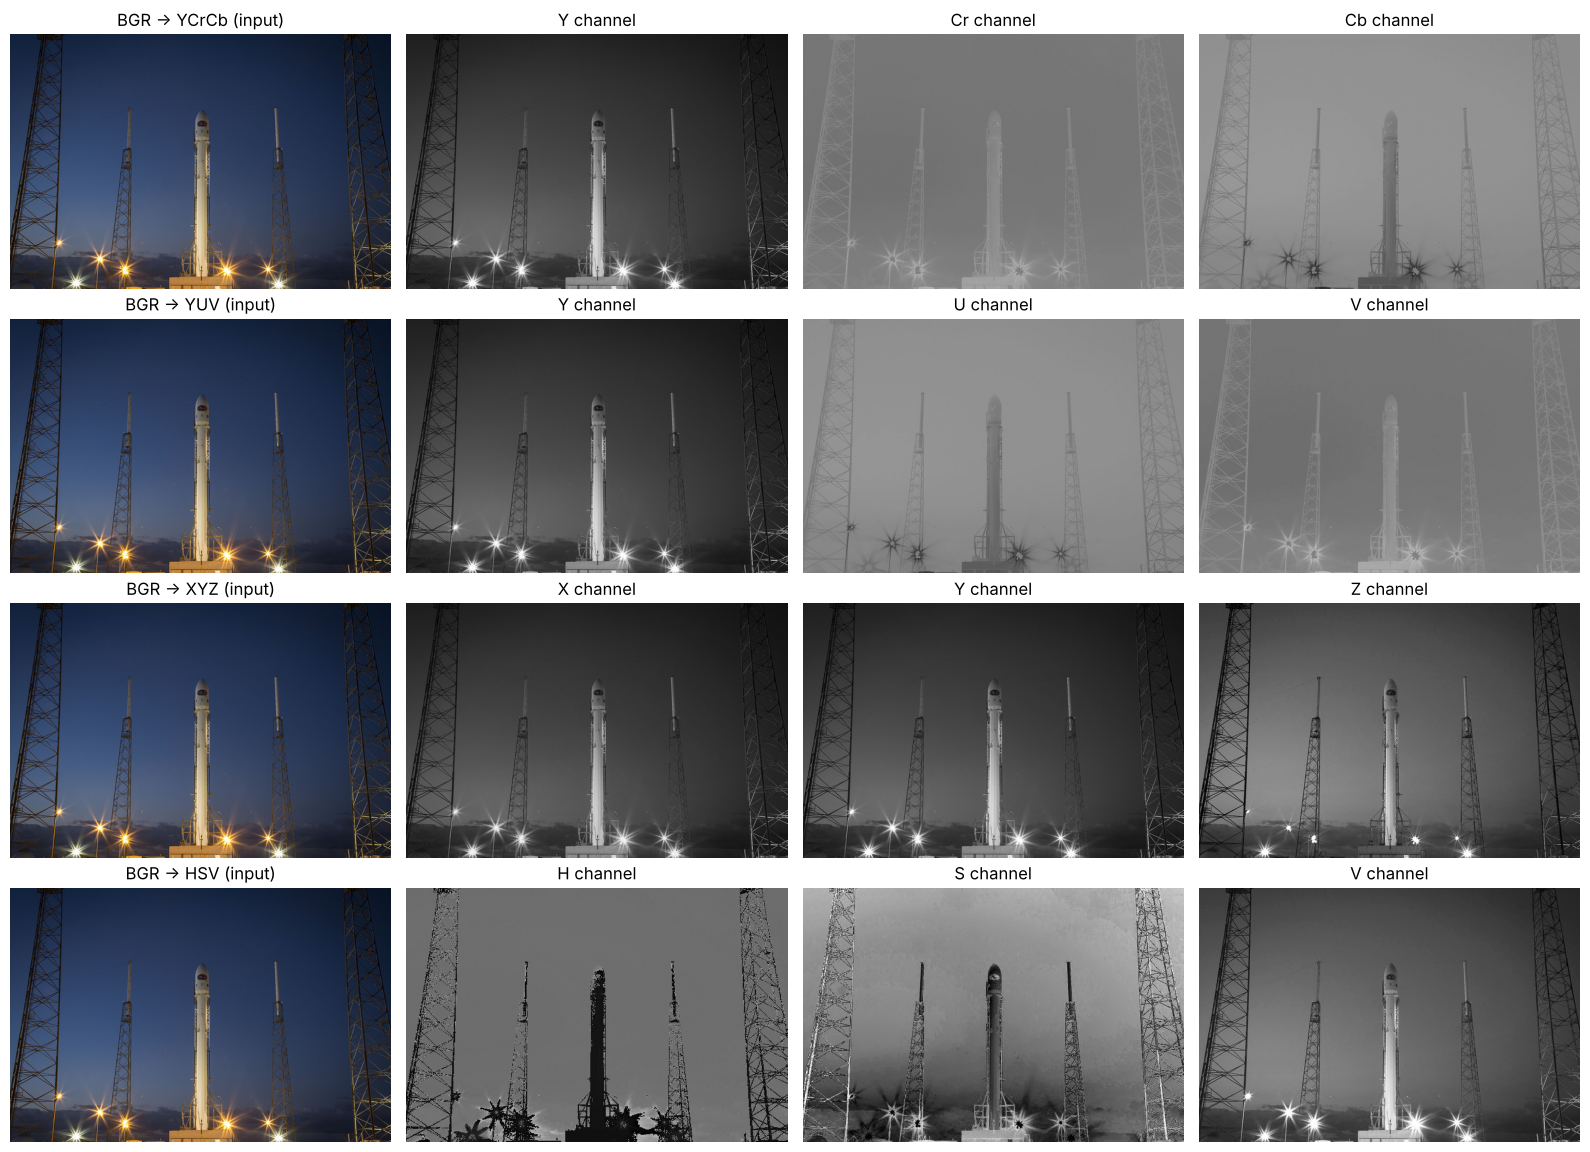

In [6]:
labels = {'BGR → YCrCb': 'Y Cr Cb', 'BGR → YUV': 'Y U V', 'BGR → XYZ': 'X Y Z', 'BGR → HSV': 'H S V'}
fig, axes = plt.subplots(len(labels), 4, figsize=(16, 2.9 * len(labels)))
for row, (name, chans) in zip(axes, labels.items()):
    row[0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    row[0].set_title(f'{name} (input)')
    for ax, channel, label in zip(row[1:], cv2.split(results[name]), chans.split()):
        ax.imshow(channel, cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'{label} channel')
    for ax in row:
        ax.axis('off')
fig.tight_layout()
fig.savefig(OUT / 'task4_color_spaces.png', dpi=90)
plt.show()

## Sonuç

Altı dönüşümün hepsinde, hem fotoğrafta hem de bütün olası renklerde, kendi fonksiyonlarımızla OpenCV arasındaki hata değeri **0** çıktı. Sıfır hata için formülün doğru olması yetmez; OpenCV'nin yuvarlama biçimi de (sabit noktalı katsayılar, `CV_DESCALE`, HSV bölme tabloları, 0–255 kırpma) aynen uygulanmalıdır. Örneğin gri dönüşümü kayan noktayla yapıldığında birkaç bin renkte 1 seviye fark oluşur (bkz. Task 3).

Bu sonuç OpenCV 4.12 ve 5.0 ile kontrol edildi.